# Riskfolio-Lib Tutorial: 
<br><a href="https://www.kqzyfj.com/click-101360347-15150084?url=https%3A%2F%2Flink.springer.com%2Fbook%2F9783031843037" target="_blank">
<div>
<img src="https://raw.githubusercontent.com/dcajasn/Riskfolio-Lib/refs/heads/master/docs/source/_static/Button.png" height="40" />
</div>
<br>
</a>
<a href="https://www.paypal.com/ncp/payment/GN55W4UQ7VAMN" target="_blank">
<div>
<img src="https://raw.githubusercontent.com/dcajasn/Riskfolio-Lib/refs/heads/master/docs/source/_static/Button2.png" height="40" />
</div>
</a>

<br><a href='https://ko-fi.com/B0B833SXD' target='_blank'><img height='36' style='border:0px;height:36px;' src='https://cdn.ko-fi.com/cdn/kofi1.png?v=2' border='0' alt='Buy Me a Coffee at ko-fi.com' /></a> 
<br>
<br>__[Financionerioncios](https://financioneroncios.wordpress.com)__
<br>__[Orenji](https://www.linkedin.com/company/orenj-i)__
<br>__[Riskfolio-Lib](https://portfoliooptimization.org)__
<br>__[Dany Cajas](https://www.linkedin.com/in/dany-cajas/)__

## Tutorial 46: Risk Parity with Risk Factors

## 1. Downloading the Data:

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import warnings

warnings.filterwarnings("ignore")
pd.options.display.float_format = '{:.4%}'.format

# Date range
start = '2016-01-01'
end = '2019-12-30'

# Tickers of assets
assets = ['JCI', 'TGT', 'CMCSA', 'CPB', 'MO', 'APA', 'MRSH', 'JPM',
          'ZION', 'PSA', 'BAX', 'BMY', 'LUV', 'PCAR', 'TXT', 'TMO',
          'DE', 'MSFT', 'HPQ', 'SHW', 'VZ', 'CNP', 'NI', 'T', 'BA']
assets.sort()

# Tickers of factors

factors = ['MTUM', 'QUAL', 'VLUE', 'SIZE', 'USMV']
factors.sort()

tickers = assets + factors
tickers.sort()

# Downloading data
data = yf.download(tickers, start = start, end = end, auto_adjust=False)
data = data.loc[:,('Adj Close', slice(None))]
data.columns = tickers

[*********************100%***********************]  30 of 30 completed


In [2]:
# Calculating returns

X = data[factors].pct_change().dropna()
Y = data[assets].pct_change().dropna()

display(X.head())

,MTUM,QUAL,SIZE,USMV,VLUE
Date,,,,,
2016-01-05,0.4735%,0.2672%,0.0000%,0.6779%,0.1634%
2016-01-06,-0.5267%,-1.1914%,-0.5380%,-0.6253%,-1.8277%
2016-01-07,-2.2293%,-2.3798%,-1.7181%,-1.6215%,-2.1609%
2016-01-08,-0.9548%,-1.1377%,-1.1978%,-1.0086%,-1.0873%
2016-01-11,0.6043%,0.1480%,-0.5898%,0.1491%,-0.6184%


## 2. Estimating Risk Parity Portfolios with Stepwise Regression

### 2.1 Estimating the loadings matrix with Stepwise Regression

This part is just to visualize how Riskfolio-Lib calculates a loadings matrix using PCR.

In [3]:
import riskfolio as rp

feature_selection = 'stepwise' # Method to select best model, could be PCR or Stepwise
stepwise = 'Forward' # Stepwise Forward regression

loadings = rp.loadings_matrix(X=X,
                              Y=Y,
                              feature_selection=feature_selection,
                              stepwise='Forward')

loadings.style.format("{:.4f}").background_gradient(cmap='RdYlGn')

,const,MTUM,QUAL,SIZE,USMV,VLUE
APA,-0.0006,-0.6551,0.0000,0.9406,-0.7883,1.7237
BA,0.0005,0.0000,1.1744,0.3616,-0.4323,0.0000
BAX,0.0003,0.3146,0.0000,0.0000,0.7716,0.0000
BMY,-0.0003,0.0000,0.8123,0.0000,0.0000,0.0000
CMCSA,0.0001,0.0000,0.4958,0.0000,0.4962,0.0000
CNP,0.0001,-0.5595,-0.2157,0.0000,1.8341,0.0000
CPB,-0.0003,-0.4782,-0.5993,0.0000,2.0793,0.0000
DE,0.0004,0.0000,0.0000,0.3631,0.0000,0.8090
HPQ,0.0002,0.0000,0.0000,0.0000,0.0000,1.2514
JCI,0.0001,0.0000,0.0000,0.3412,0.0000,0.5797


### 2.2 Calculating the Factor Risk Parity Portfolio based on Market Factors

In [4]:
# Building the portfolio object
port = rp.Portfolio(returns=Y)

# Calculating optimal portfolio

# Select method and estimate input parameters:

method_mu='hist' # Method to estimate expected returns based on historical data.
method_cov='hist' # Method to estimate covariance matrix based on historical data.

port.assets_stats(method_mu=method_mu,
                  method_cov=method_cov)

feature_selection = 'stepwise' # Method to select best model, could be PCR or Stepwise
stepwise = 'Forward' # Forward or Backward regression

port.factors = X
port.factors_stats(method_mu=method_mu,
                   method_cov=method_cov,
                   dict_load=dict(feature_selection=feature_selection,
                                  stepwise=stepwise,
                                  )
                  )

# Estimate optimal portfolio:

model = 'FC' # Factor Contribution Model
rm = 'MV' # Risk measure used, this time will be variance
rf = 0 # Risk free rate
b_f = None # Risk factor contribution vector

w = port.rp_optimization(model=model,
                         rm=rm,
                         rf=rf,
                         b_f=b_f,
                         )

display(w.T)

,APA,BA,BAX,BMY,CMCSA,CNP,CPB,DE,HPQ,JCI,...,NI,PCAR,PSA,SHW,T,TGT,TMO,TXT,VZ,ZION
weights,3.2987%,5.6171%,11.6391%,1.2930%,4.2481%,1.3079%,4.0257%,8.7804%,3.0801%,7.8051%,...,5.3583%,-4.5189%,4.1032%,8.4341%,-3.9166%,1.8613%,9.2573%,6.5554%,-2.1153%,0.2524%


### 2.3 Plotting Portfolio Composition

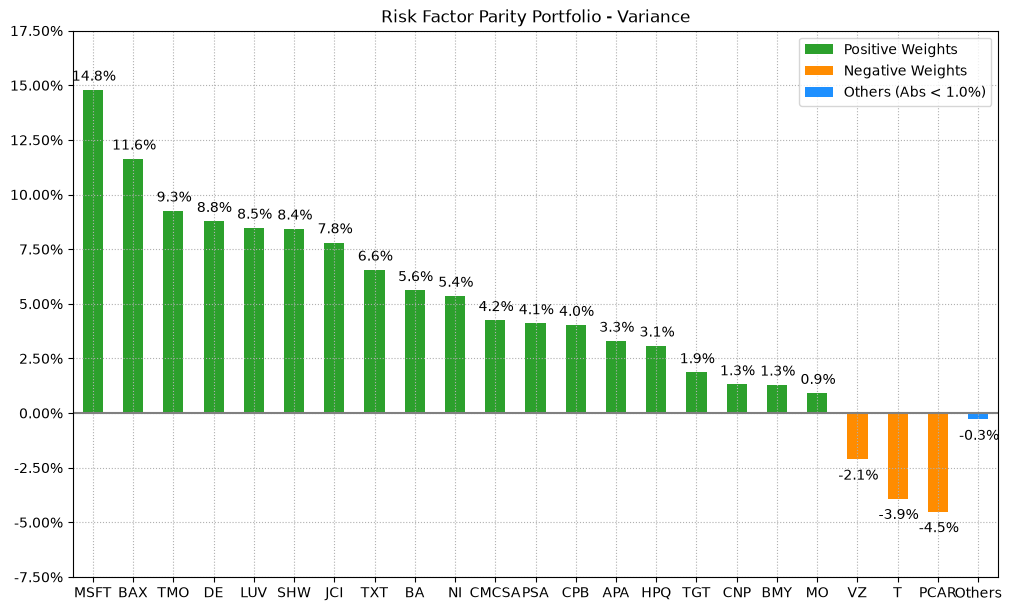

In [5]:
# Plotting the composition of the portfolio
ax = rp.plot_bar(w,
                 title='Risk Factor Parity Portfolio - Variance',
                 kind="v",
                 others=0.05,
                 nrow=25,
                 height=6,
                 width=10,
                 ax=None)

### 2.3 Calculate the Risk Contribution per Asset

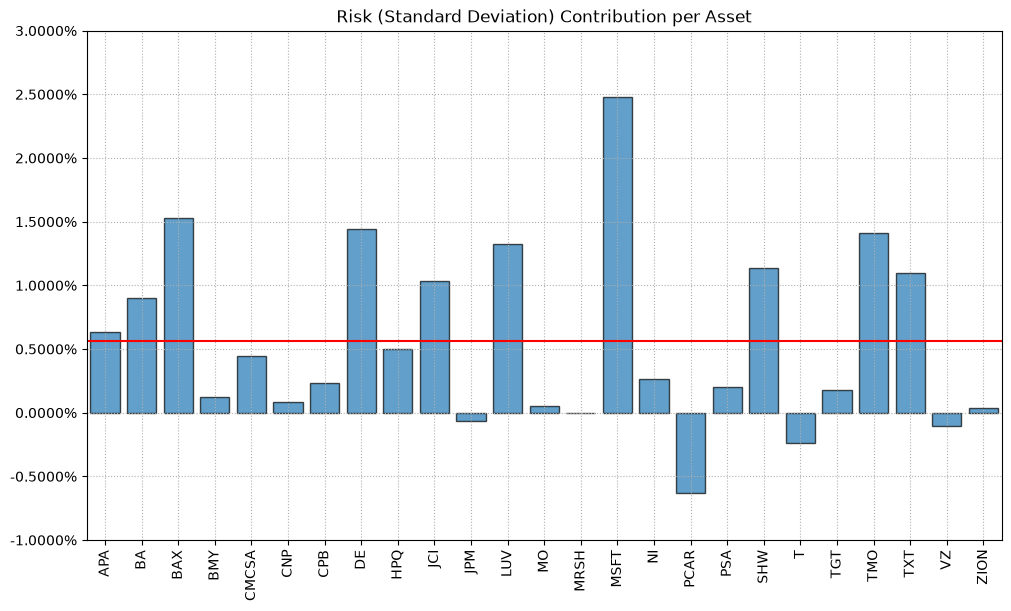

In [6]:
ax = rp.plot_risk_con(
    w=w,
    cov=port.cov,
    returns=port.returns,
    rm=rm,
    rf=0,
    alpha=0.05,
    color="tab:blue",
    height=6,
    width=10,
    ax=None)

### 2.4 Calculate the Risk Contribution per Risk Factor

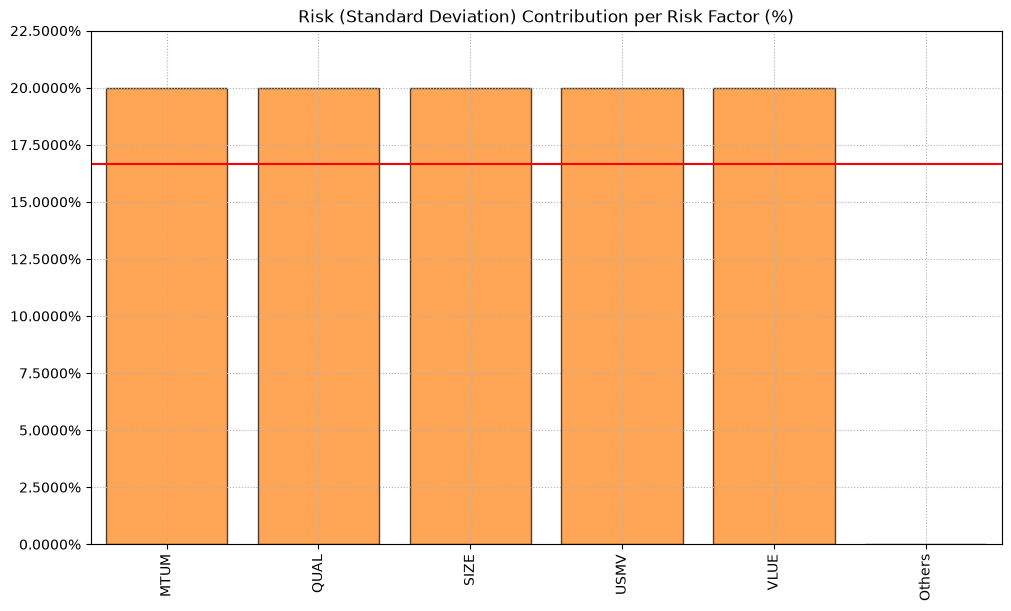

In [7]:
ax = rp.plot_factor_risk_con(
    w,
    cov=port.cov,
    returns=port.returns,
    factors=port.factors,
    rm=rm,
    rf=0,
    feature_selection=feature_selection,
    stepwise=stepwise,
    percentage=True,
    erc_line=True,
    color="tab:orange",
    ax=None,
)

## 3. Estimating Portfolios Using Risk Factors with Other Risk Measures and Stepwise Regression

In this part I will calculate optimal factor risk parity portfolios for several risk measures using the market factors matrix as risk factors.

### 3.1 Calculate Optimal Factor Risk Parity Portfolios based on Market Factors for Several Risk Measures

In [8]:
# Risk Measures available:
#
# 'MV': Standard Deviation.
# 'MAD': Mean Absolute Deviation.
# 'MSV': Semi Standard Deviation.
# 'FLPM': First Lower Partial Moment (Omega Ratio).
# 'SLPM': Second Lower Partial Moment (Sortino Ratio).
# 'CVaR': Conditional Value at Risk.
# 'EVaR': Entropic Value at Risk.
# 'WR': Worst Realization (Minimax)
# 'MDD': Maximum Drawdown of uncompounded cumulative returns (Calmar Ratio).
# 'ADD': Average Drawdown of uncompounded cumulative returns.
# 'CDaR': Conditional Drawdown at Risk of uncompounded cumulative returns.
# 'EDaR': Entropic Drawdown at Risk of uncompounded cumulative returns.
# 'UCI': Ulcer Index of uncompounded cumulative returns.

rms = ['MV', 'MAD', 'MSV', 'FLPM', 'SLPM', 'CVaR',
       'EVaR', 'CDaR', 'UCI', 'EDaR']

w_s = pd.DataFrame([])

# When we use hist = True the risk measures all calculated
# using historical returns, while when hist = False the
# risk measures are calculated using the expected returns 
#  based on risk factor model: R = a + B * F

for i in rms:
    w = port.rp_optimization(model=model, rm=i, rf=rf, b_f=b_f)
    w_s = pd.concat([w_s, w], axis=1)
    
w_s.columns = rms

In [9]:
w_s.style.format("{:.2%}").background_gradient(cmap='YlGn')

,MV,MAD,MSV,FLPM,SLPM,CVaR,EVaR,CDaR,UCI,EDaR
APA,3.30%,2.62%,3.52%,2.13%,3.30%,3.81%,5.36%,0.03%,0.08%,0.34%
BA,5.62%,5.55%,5.63%,5.48%,5.57%,5.49%,6.14%,4.41%,4.42%,4.88%
BAX,11.64%,11.09%,11.87%,11.04%,11.86%,12.32%,12.93%,12.80%,13.09%,12.81%
BMY,1.29%,1.75%,1.11%,1.92%,1.17%,0.74%,0.24%,1.37%,1.30%,1.50%
CMCSA,4.25%,4.40%,4.19%,4.49%,4.23%,4.08%,3.90%,4.58%,4.55%,4.65%
CNP,1.31%,1.33%,1.30%,1.27%,1.29%,1.28%,1.21%,1.08%,0.68%,0.92%
CPB,4.03%,3.67%,4.17%,3.53%,4.12%,4.45%,4.78%,4.09%,3.80%,3.86%
DE,8.78%,8.21%,9.00%,8.01%,8.92%,9.39%,10.28%,8.39%,8.66%,8.50%
HPQ,3.08%,3.50%,2.92%,3.70%,3.02%,2.77%,1.81%,4.14%,4.35%,3.89%
JCI,7.81%,7.21%,8.03%,6.99%,7.94%,8.42%,9.39%,7.28%,7.51%,7.42%


<Axes: >

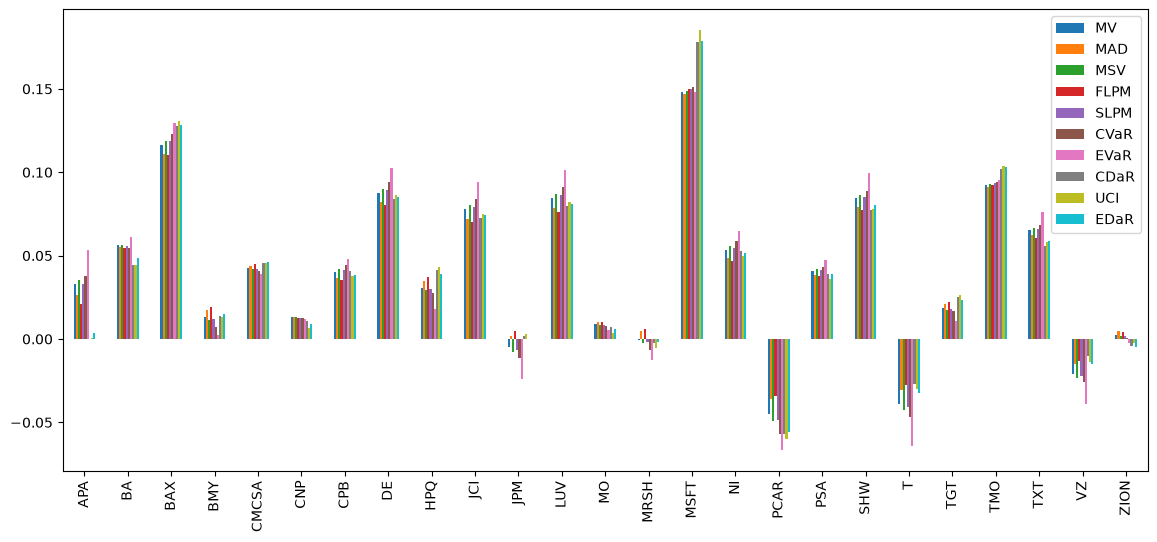

In [10]:
import matplotlib.pyplot as plt

# Plotting a comparison of assets weights for each portfolio

fig = plt.gcf()
fig.set_figwidth(14)
fig.set_figheight(6)
ax = fig.subplots(nrows=1, ncols=1)

w_s.plot.bar(ax=ax)

## 4. Estimating Risk Parity Portfolios with PCR Regression

### 4.1 Estimating the Loadings Matrix with PCR

This part is just to visualize how Riskfolio-Lib calculates a loadings matrix using PCR.

In [11]:
feature_selection = 'PCR' # Method to select best model, could be PCR or Stepwise
n_components = 0.95 # 95% of explained variance. See PCA in scikit learn for more information

loadings = rp.loadings_matrix(X=X,
                              Y=Y,
                              feature_selection=feature_selection,
                              n_components=n_components)

loadings.style.format("{:.4f}").background_gradient(cmap='RdYlGn')

,const,MTUM,QUAL,SIZE,USMV,VLUE
APA,-0.0006,-0.6177,0.3849,1.0862,-1.1440,1.4544
BA,0.0005,0.2237,0.3104,0.2056,-0.0523,0.4585
BAX,0.0003,0.3088,0.1876,0.0765,0.5225,-0.0462
BMY,-0.0003,0.0716,0.1550,0.2642,0.3030,0.1029
CMCSA,0.0001,0.0826,0.1751,0.2756,0.2804,0.1425
CNP,0.0001,-0.2226,-0.0563,0.5693,1.1198,-0.4871
CPB,-0.0003,-0.2159,-0.0891,0.5283,1.1886,-0.5772
DE,0.0005,0.0756,0.3325,0.3343,-0.3699,0.7044
HPQ,0.0002,0.1800,0.3987,0.2754,-0.4648,0.8129
JCI,0.0000,-0.0535,0.2148,0.4091,-0.0641,0.4253


### 4.2 Calculating the Factor Risk Parity Portfolio based on Principal Components

In [12]:
feature_selection = 'PCR' # Method to select best model, could be PCR or Stepwise
n_components = 0.95 # 95% of explained variance. See PCA in scikit learn for more information

port.factors = X
port.factors_stats(method_mu=method_mu,
                   method_cov=method_cov,
                   dict_load=dict(feature_selection=feature_selection,
                                  stepwise=stepwise,
                                  )
                  )

# Estimate optimal portfolio:

model = 'FC' # Factor Contribution Model
rm = 'MV' # Risk measure used, this time will be variance
rf = 0 # Risk free rate
b_f = None # Risk factor contribution vector

w = port.rp_optimization(model=model,
                         rm=rm,
                         rf=rf,
                         b_f=b_f,
                         )

display(w.T)

,APA,BA,BAX,BMY,CMCSA,CNP,CPB,DE,HPQ,JCI,...,NI,PCAR,PSA,SHW,T,TGT,TMO,TXT,VZ,ZION
weights,3.2987%,5.6171%,11.6391%,1.2930%,4.2481%,1.3079%,4.0257%,8.7804%,3.0801%,7.8051%,...,5.3583%,-4.5189%,4.1032%,8.4341%,-3.9166%,1.8613%,9.2573%,6.5554%,-2.1153%,0.2524%


### 4.3 Plotting portfolio composition

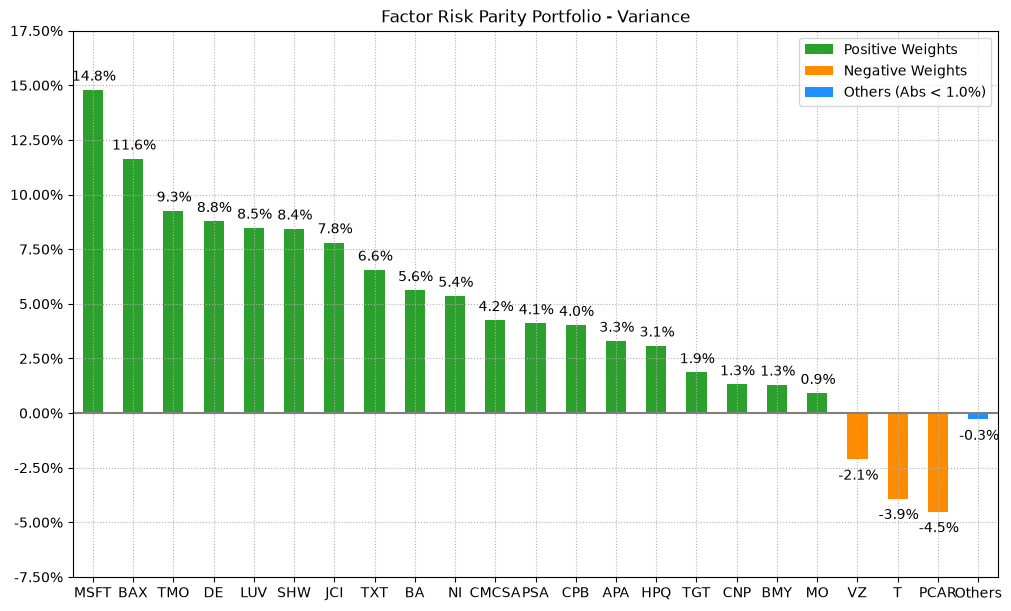

In [13]:
# Plotting the composition of the portfolio
ax = rp.plot_bar(w,
                 title='Factor Risk Parity Portfolio - Variance',
                 kind="v",
                 others=0.05,
                 nrow=25,
                 height=6,
                 width=10,
                 ax=None)

### 4.4 Calculate the risk contribution per asset

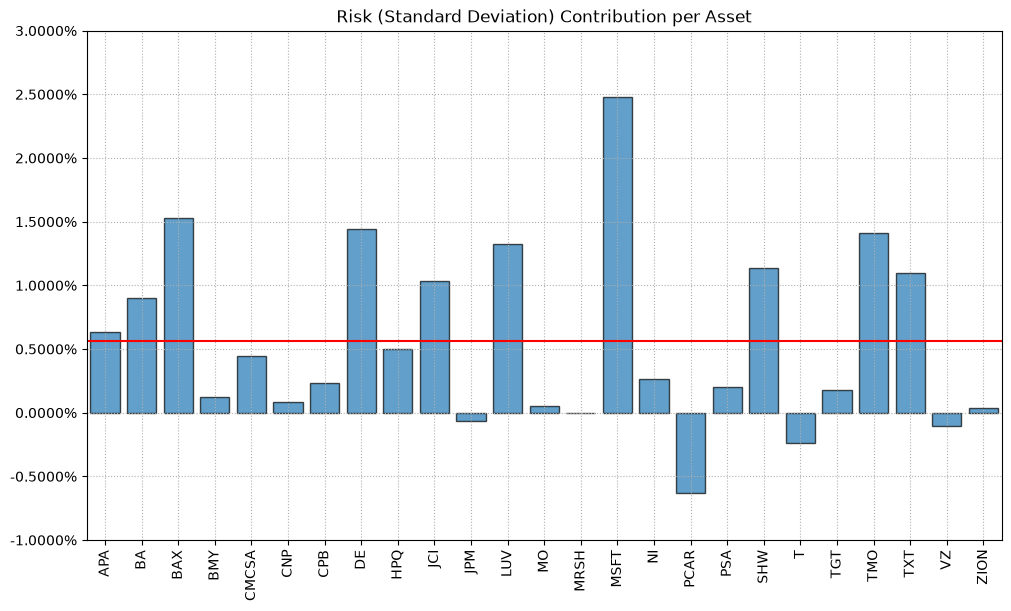

In [14]:
ax = rp.plot_risk_con(
    w=w,
    cov=port.cov,
    returns=port.returns,
    rm=rm,
    rf=0,
    alpha=0.05,
    color="tab:blue",
    height=6,
    width=10,
    ax=None)

### 4.5 Calculate the risk contribution per principal component

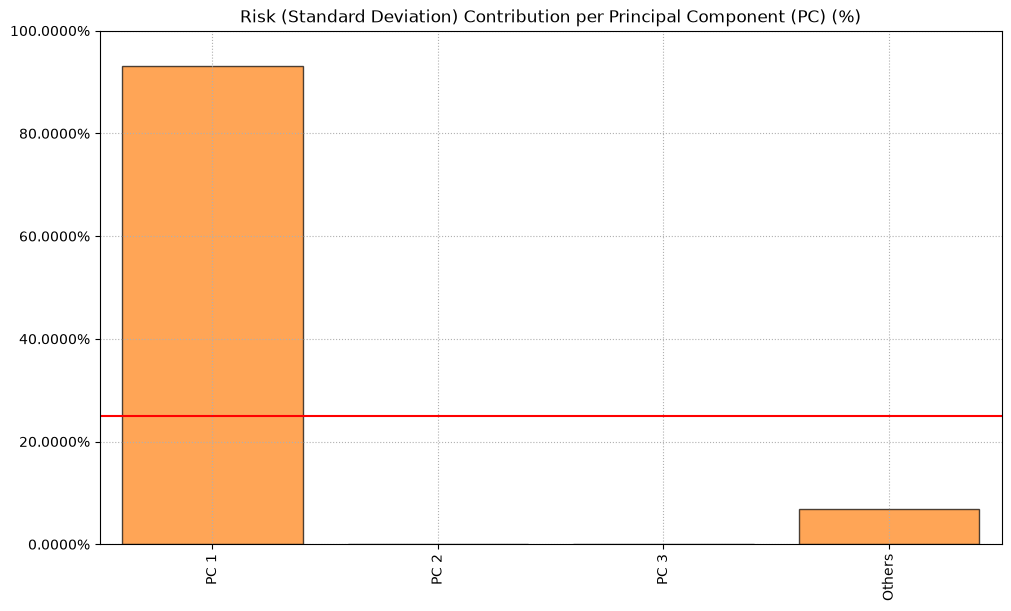

In [15]:
ax = rp.plot_factor_risk_con(
    w,
    cov=port.cov,
    returns=port.returns,
    factors=port.factors,
    rm=rm,
    rf=0,
    feature_selection=feature_selection,
    stepwise=stepwise,
    percentage=True,
    erc_line=True,
    color="tab:orange",
    ax=None,
)

## 5. Estimating Portfolios Using Risk Factors with Other Risk Measures and PCR

In this part I will calculate optimal factor risk parity portfolios for several risk measures using the principal components of market factors matrix as risk factors.

### 5.1 Calculate Optimal Factor Risk Parity Portfolios based on Principal Components for Several Risk Measures.

In [16]:
# Risk Measures available:
#
# 'MV': Standard Deviation.
# 'MAD': Mean Absolute Deviation.
# 'MSV': Semi Standard Deviation.
# 'FLPM': First Lower Partial Moment (Omega Ratio).
# 'SLPM': Second Lower Partial Moment (Sortino Ratio).
# 'CVaR': Conditional Value at Risk.
# 'EVaR': Entropic Value at Risk.
# 'WR': Worst Realization (Minimax)
# 'MDD': Maximum Drawdown of uncompounded cumulative returns (Calmar Ratio).
# 'ADD': Average Drawdown of uncompounded cumulative returns.
# 'CDaR': Conditional Drawdown at Risk of uncompounded cumulative returns.
# 'EDaR': Entropic Drawdown at Risk of uncompounded cumulative returns.
# 'UCI': Ulcer Index of uncompounded cumulative returns.

rms = ['MV', 'MAD', 'MSV', 'FLPM', 'SLPM', 'CVaR',
       'EVaR', 'CDaR', 'UCI', 'EDaR']

w_s = pd.DataFrame([])

# When we use hist = True the risk measures all calculated
# using historical returns, while when hist = False the
# risk measures are calculated using the expected returns 
#  based on risk factor model: R = a + B * F

for i in rms:
    w = port.rp_optimization(model=model, rm=i, rf=rf, b_f=b_f)
    w_s = pd.concat([w_s, w], axis=1)
    
w_s.columns = rms

In [17]:
w_s.style.format("{:.2%}").background_gradient(cmap='YlGn')

,MV,MAD,MSV,FLPM,SLPM,CVaR,EVaR,CDaR,UCI,EDaR
APA,3.30%,2.62%,3.52%,2.13%,3.30%,3.81%,5.36%,0.03%,0.08%,0.34%
BA,5.62%,5.55%,5.63%,5.48%,5.57%,5.49%,6.14%,4.41%,4.42%,4.88%
BAX,11.64%,11.09%,11.87%,11.04%,11.86%,12.32%,12.93%,12.80%,13.09%,12.81%
BMY,1.29%,1.75%,1.11%,1.92%,1.17%,0.74%,0.24%,1.37%,1.30%,1.50%
CMCSA,4.25%,4.40%,4.19%,4.49%,4.23%,4.08%,3.90%,4.58%,4.55%,4.65%
CNP,1.31%,1.33%,1.30%,1.27%,1.29%,1.28%,1.21%,1.08%,0.68%,0.92%
CPB,4.03%,3.67%,4.17%,3.53%,4.12%,4.45%,4.78%,4.09%,3.80%,3.86%
DE,8.78%,8.21%,9.00%,8.01%,8.92%,9.39%,10.28%,8.39%,8.66%,8.50%
HPQ,3.08%,3.50%,2.92%,3.70%,3.02%,2.77%,1.81%,4.14%,4.35%,3.89%
JCI,7.81%,7.21%,8.03%,6.99%,7.94%,8.42%,9.39%,7.28%,7.51%,7.42%


<Axes: >

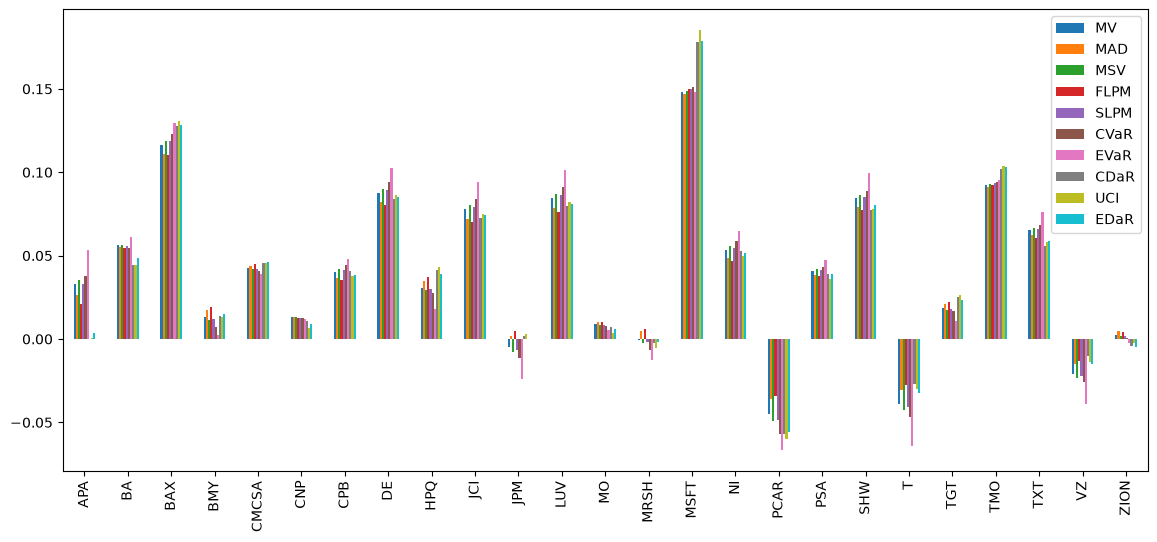

In [18]:
import matplotlib.pyplot as plt

# Plotting a comparison of assets weights for each portfolio

fig = plt.gcf()
fig.set_figwidth(14)
fig.set_figheight(6)
ax = fig.subplots(nrows=1, ncols=1)

w_s.plot.bar(ax=ax)